# 05 · Frozen test replay, uncertainty and failures
## Summary
Evaluate the frozen candidate and baselines on the previously explored chronological test. Archive point/quantile predictions first, then join outcomes. Compare rolling past out-of-sample error intervals with 5th/50th/95th quantile forecasts. Assess paired improvement using contiguous multi-day blocks rather than independent hourly resampling.
## Context and methods
90% is a nominal interval level, not guaranteed conditional coverage. Calibration uses only errors whose labels are available before each origin. Daily energy and daily maximum require whole residual trajectories; adding hourly quantiles is not a valid daily interval. Full daily residual scenarios preserve cross-hour dependence, while days with too little matching DST history remain unsupported.

References: [quantile regression](https://scikit-learn.org/stable/auto_examples/ensemble/plot_gradient_boosting_quantile.html), [adaptive conformal inference](https://arxiv.org/abs/2106.00170), [time-series bootstrapping](https://otexts.com/fpp3/bootstrap.html). No conformal guarantee is claimed for this empirical implementation.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config/forecast_contract.json").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.common import load_contract, prepare_directories, plotting_style, write_json, fingerprint
contract = load_contract(ROOT)
prepare_directories(ROOT)
plotting_style()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 16)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
from src.storage import read_features,read_labels,read_predictions
from src.backtest import Experiment,baseline_replay,model_replay,archive_predictions
from src.metrics import scorecard,matched_scorecard,segment_scorecard,daily_metrics,paired_block_bootstrap
from src.uncertainty import empirical_intervals,interval_scorecard,trajectory_intervals
features=read_features(ROOT/"data/origin_snapshots/history_features.csv.gz")
labels=read_labels(ROOT/"data/processed/evaluation_labels.csv.gz")
frozen=json.loads((ROOT/"config/frozen_candidate.json").read_text())
assert frozen["contract_sha256"]==fingerprint(ROOT/"config/forecast_contract.json")
selected=Experiment(**frozen["experiment"])
start=contract["test"]["start"]; end=contract["test"]["end"]

### 1. Save frozen point and quantile forecasts before scoring

In [3]:
baselines=baseline_replay(features,start,end,ROOT,contract,phase="test")
candidate=model_replay(features,labels,start,end,selected,ROOT,contract,phase="test",quantiles=True)
test_predictions=pd.concat([baselines,candidate],ignore_index=True)
archive_predictions(ROOT,"all_test",test_predictions,contract)

PosixPath('/Users/alivakof/Desktop/Time Series/Project/reports/forecasts/all_test.csv.gz')

### 2. Matched point scores, critical segments and daily outcomes

In [4]:
scores=scorecard(test_predictions,labels)
matched_scores,matched=matched_scorecard(test_predictions,labels)
raw_scores,raw_matched=matched_scorecard(test_predictions,labels,"raw_prediction_mw")
segments=segment_scorecard(test_predictions,labels,contract)
daily=daily_metrics(test_predictions,labels)
for name,table in (("test_policy",scores),("test_common",matched_scores),("test_common_raw",raw_scores),("test_segments",segments),("test_daily",daily)):
    table.to_csv(ROOT/f"reports/scorecards/{name}.csv",index=False)
display(matched_scores); display(daily.groupby("model").mean(numeric_only=True))
ci=paired_block_bootstrap(test_predictions,labels,selected.name,block_days=contract["bootstrap_block_days"],repetitions=contract["bootstrap_repetitions"],seed=contract["random_seed"])
ci.to_csv(ROOT/"reports/scorecards/paired_block_bootstrap.csv",index=False)
display(ci)

,model,eligible_targets,scored,missing_targets,availability,MAE_MW,RMSE_MW,bias_actual_minus_forecast_MW,WAPE_percent
0,seasonal_naive,"8,759.000","8,759.000",1.000,1.000,"3,424.948","5,060.040",52.071,6.760
1,comparable_days,"8,759.000","8,759.000",1.000,1.000,"3,818.657","5,374.144",94.938,7.537
2,rte_proxy,"8,759.000","8,759.000",1.000,1.000,"1,438.982","1,782.647","1,085.830",2.840
3,rte_bias_proxy,"8,759.000","8,759.000",1.000,1.000,"1,111.048","1,412.837",3.636,2.193
4,rte_correction_proxy,"8,759.000","8,759.000",1.000,1.000,832.047,"1,090.315",134.827,1.642


,hours,absolute_daily_energy_error_MWh,absolute_daily_peak_error_MW,ramp_MAE_MW,shortage_proxy_MWh,surplus_proxy_MWh
model,,,,,,
comparable_days,23.997,"89,098.136","3,850.000",370.311,"46,817.441","44,802.272"
rte_bias_proxy,23.997,"14,663.802",998.322,617.059,"13,395.865","13,297.927"
rte_correction_proxy,23.997,"14,578.204",957.110,368.788,"11,617.735","8,377.796"
rte_proxy,23.997,"27,757.440","1,723.104",617.059,"30,323.209","4,245.335"
seasonal_naive,23.997,"79,077.852","3,507.772",339.110,"41,659.143","40,581.093"


,block_days,status,paired_days,partially_observed_days_retained,paired_hours,relative_improvement_percent,relative_low,relative_high,absolute_MAE_improvement_MW,absolute_low,absolute_high
0,7,ok,365,1,8759,42.178,38.173,46.407,606.935,534.154,687.818
1,14,ok,365,1,8759,42.178,37.360,47.533,606.935,535.431,703.937
2,28,ok,365,1,8759,42.178,35.625,48.672,606.935,511.049,731.956


### 3. Uncertainty baseline from past out-of-sample errors

,segment_type,segment,eligible_targets,scored,interval_availability,coverage_90,width_MW,lower_exceedance,upper_exceedance,pinball_0.05,pinball_0.50,pinball_0.95
0,overall,all,8759,8759,1.000,0.811,"2,811.492",0.080,0.110,108.780,416.024,127.458
1,hour,0,365,365,1.000,0.885,"2,184.019",0.027,0.088,70.532,297.180,74.021
2,hour,1,365,365,1.000,0.863,"2,097.691",0.090,0.047,73.386,307.905,73.141
3,hour,2,364,364,1.000,0.849,"2,078.303",0.049,0.102,68.910,298.804,81.417
4,hour,3,365,365,1.000,0.868,"2,081.365",0.055,0.077,65.801,298.478,79.811


,segment_type,segment,eligible_targets,scored,interval_availability,coverage_90,width_MW,lower_exceedance,upper_exceedance,pinball_0.05,pinball_0.50,pinball_0.95
0,overall,all,8759,8759,1.000,0.890,"3,475.690",0.050,0.060,114.916,415.620,125.955
1,hour,0,365,365,1.000,0.975,"3,475.741",0.016,0.008,84.122,304.980,98.079
2,hour,1,365,365,1.000,0.964,"3,475.741",0.022,0.014,85.498,318.179,101.708
3,hour,2,364,364,1.000,0.967,"3,474.518",0.008,0.025,90.178,298.759,94.357
4,hour,3,365,365,1.000,0.964,"3,475.741",0.008,0.027,82.665,308.964,103.532


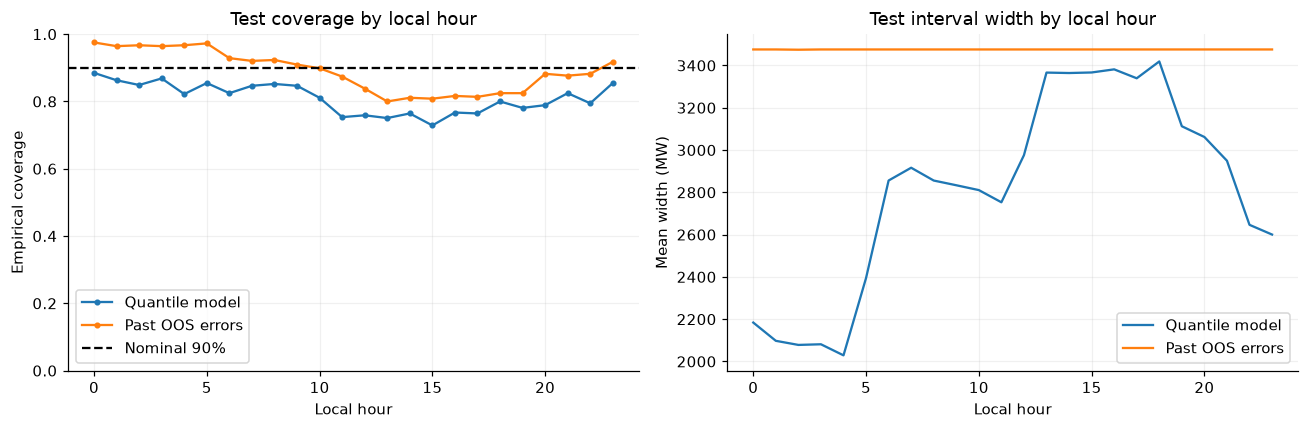

In [5]:
validation=read_predictions(ROOT/"reports/forecasts/all_validation.csv.gz")
past=validation.loc[validation.model.eq(selected.name)]
point_intervals=empirical_intervals(candidate.drop(columns=["q05","q50","q95"]),past,labels,contract)
archive_predictions(ROOT,"candidate_empirical_intervals_test",point_intervals,contract)
quantile_scores=interval_scorecard(candidate,labels,contract)
empirical_scores=interval_scorecard(point_intervals,labels,contract)
quantile_scores.to_csv(ROOT/"reports/uncertainty/quantile_calibration.csv",index=False)
empirical_scores.to_csv(ROOT/"reports/uncertainty/empirical_calibration.csv",index=False)
display(quantile_scores.head()); display(empirical_scores.head())
fig,axes=plt.subplots(1,2,figsize=(12,4))
for table,label in ((quantile_scores,"Quantile model"),(empirical_scores,"Past OOS errors")):
    h=table.loc[table.segment_type.eq("hour")].copy(); h["hour"]=h.segment.astype(int); h=h.sort_values("hour")
    axes[0].plot(h.hour,h.coverage_90,marker=".",label=label)
    axes[1].plot(h.hour,h.width_MW,label=label)
axes[0].axhline(.9,color="black",linestyle="--",label="Nominal 90%")
axes[0].set(title="Test coverage by local hour",xlabel="Local hour",ylabel="Empirical coverage",ylim=(0,1)); axes[0].legend()
axes[1].set(title="Test interval width by local hour",xlabel="Local hour",ylabel="Mean width (MW)"); axes[1].legend()
plt.tight_layout(); plt.show()

### 4. Daily trajectory uncertainty, saved before daily outcome comparison

In [6]:
trajectory=trajectory_intervals(candidate,past,labels,contract)
trajectory.to_csv(ROOT/"reports/uncertainty/daily_trajectory_predictions.csv",index=False)
truth=labels.copy(); truth["day"]=truth.delivery_time.dt.tz_convert(contract["timezone"]).dt.strftime("%Y-%m-%d")
actual_daily=truth.groupby("day").agg(actual_energy_MWh=("actual_mw",lambda s:s.sum(min_count=len(s))),actual_peak_MW=("actual_mw","max"),valid_hours=("actual_mw","count"))
trajectory_eval=trajectory.merge(actual_daily,left_on="day",right_index=True,how="left")
ok=trajectory_eval.status.eq("ok") & trajectory_eval.valid_hours.eq(trajectory_eval.hours)
trajectory_eval["energy_covered"]=np.where(ok,trajectory_eval.actual_energy_MWh.between(trajectory_eval.energy_q05_MWh,trajectory_eval.energy_q95_MWh),np.nan)
trajectory_eval["peak_covered"]=np.where(ok,trajectory_eval.actual_peak_MW.between(trajectory_eval.peak_q05_MW,trajectory_eval.peak_q95_MW),np.nan)
trajectory_eval.to_csv(ROOT/"reports/uncertainty/daily_trajectory_evaluation.csv",index=False)
display(trajectory_eval.groupby(["status","hours"]).agg(days=("day","size"),energy_coverage=("energy_covered","mean"),peak_coverage=("peak_covered","mean")))

days  energy_coverage  peak_coverage
status               hours                                      
insufficient_history 23        1              NaN            NaN
                     25        1              NaN            NaN
ok                   24      363            0.917          0.909

### 5. Inspect failures without inventing causes

,MAE_MW,max_error_MW,fallback_intervals,minimum_temperature_C,source_reconciliation_flags,scored_intervals,classification,weather_miss_verified
day,,,,,,,,
2025-12-01,"2,688.154","4,067.601",0,2.700,0,24,unexplained,False
2026-01-05,"2,685.565","5,619.096",0,-3.540,0,24,unexplained,False
2025-12-26,"2,432.148","5,535.420",0,-0.330,0,24,unexplained,False
2026-05-01,"2,339.428","3,567.615",0,12.030,0,24,unexplained,False
2025-10-27,"2,337.765","3,987.188",0,9.500,0,24,unexplained,False
2025-11-01,"2,299.413","3,197.413",0,12.650,0,24,unexplained,False
2026-01-04,"2,298.102","4,546.061",0,-3.410,0,24,unexplained,False
2026-01-10,"2,097.082","3,225.543",0,2.170,0,24,unexplained,False
2025-11-29,"2,050.316","3,209.051",0,6.360,0,24,unexplained,False


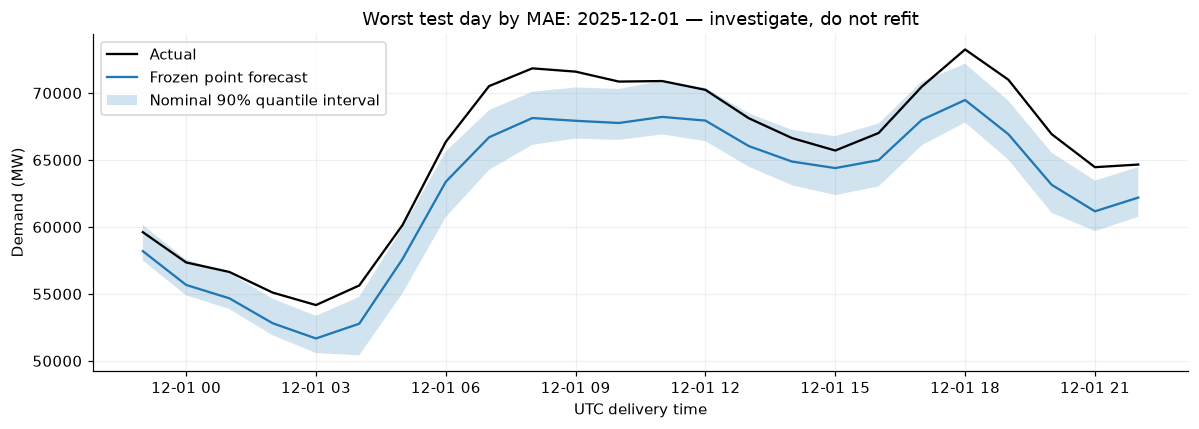

In [7]:
errors=candidate.merge(labels,on="delivery_time",validate="many_to_one")
errors["absolute_error_MW"]=(errors.actual_mw-errors.prediction_mw).abs()
errors["day"]=errors.delivery_time.dt.tz_convert(contract["timezone"]).dt.strftime("%Y-%m-%d")
failures=errors.groupby("day").agg(MAE_MW=("absolute_error_MW","mean"),max_error_MW=("absolute_error_MW","max"),fallback_intervals=("fallback_used","sum"),minimum_temperature_C=("realized_temperature_c","min"),source_reconciliation_flags=("reconciliation_flag","sum"),scored_intervals=("actual_mw","count")).sort_values("MAE_MW",ascending=False).head(10)
failures["classification"]=np.where(failures.fallback_intervals.gt(0),"fallback/input gap observed",np.where(failures.source_reconciliation_flags.gt(0),"source inconsistency observed; cause unverified","unexplained"))
failures["weather_miss_verified"]=False
failures.to_csv(ROOT/"reports/failure_catalogue.csv")
display(failures)
worst=errors.loc[errors.day.eq(failures.index[0])].sort_values("delivery_time")
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(worst.delivery_time,worst.actual_mw,label="Actual",color="black")
ax.plot(worst.delivery_time,worst.prediction_mw,label="Frozen point forecast")
ax.fill_between(worst.delivery_time,worst.q05,worst.q95,alpha=.2,label="Nominal 90% quantile interval")
ax.set(title=f"Worst test day by MAE: {failures.index[0]} — investigate, do not refit",ylabel="Demand (MW)",xlabel="UTC delivery time")
ax.legend(); plt.tight_layout(); plt.show()

## Takeaways
Point metrics, interval calibration, daily trajectory risks and paired improvement uncertainty answer different questions. Cold-evening segments use recorded weather only for retrospective diagnosis; operational cold alerts cannot be evaluated without accessible forecast weather. Neither a shaded interval nor the word conformal establishes conditional or simultaneous coverage. Worst-day classes above describe evidence, not verified root causes.